<img src="../res/logo.jpg" alt="Volcanicus" width="50%">

# Episodes

An **episode** is a period of unusual activity: a run of consecutive scenes that are anomalous for their volcano. Instead of one sample per date, an episode gives one sample per *event*, with a start, an end and a peak.

This notebook covers `scenes_anomaly_score()` and `episodes()`. They build on the anomalies of [anomalies.ipynb](anomalies.ipynb), so read that first.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import volcanicus

# corrupted rays would produce fake anomalies: mask them first
volcano = volcanicus.datasets.load("kadovar").mask_rays()
volcano

dates,81
missing,916
registers,648


## One score per scene

`scenes_anomaly_score()` boils every scene's anomalies down to a single number: the anomalies are reduced across the 8 directions (median by default) and the score is the maximum of that profile over distance. A score of `z` means that, at some distance, at least half the directions sit `z` usual deviations above normal.

The median makes the score robust to a single odd ray. The price: heat going only one way (a lava flow down one flank) can slip through; `how="max"` catches it, with more false alarms (see below).

In [2]:
score = volcano.scenes_anomaly_score()
score.describe().round(2)

count    81.00
mean      1.77
std       1.68
min       0.26
25%       0.59
50%       1.03
75%       2.45
max       7.27
Name: score, dtype: float64

## Episodes

`episodes(threshold=3.0, max_gap=90)` marks every scene scoring above `threshold` as anomalous and groups consecutive anomalous scenes into episodes. An episode ends at the first scene that isn't anomalous, or when two anomalous scenes are more than `max_gap` days apart with nothing observed in between (there's no telling what happened in such a gap).

In [3]:
episodes = volcano.episodes()
episodes.round(1)

,start,end,duration_days,n_scenes,peak_date,peak_score
0,2018-05-27,2018-10-02,128,4,2018-10-02,7.3
1,2019-07-17,2019-07-17,0,1,2019-07-17,4.7
2,2019-09-03,2019-09-03,0,1,2019-09-03,6.6
3,2020-12-10,2020-12-10,0,1,2020-12-10,3.1
4,2021-09-08,2021-09-08,0,1,2021-09-08,3.9
5,2022-08-26,2022-08-26,0,1,2022-08-26,3.2
6,2022-09-19,2022-09-19,0,1,2022-09-19,3.1
7,2023-05-09,2023-05-09,0,1,2023-05-09,7.1
8,2024-08-15,2024-10-02,48,3,2024-09-24,6.6


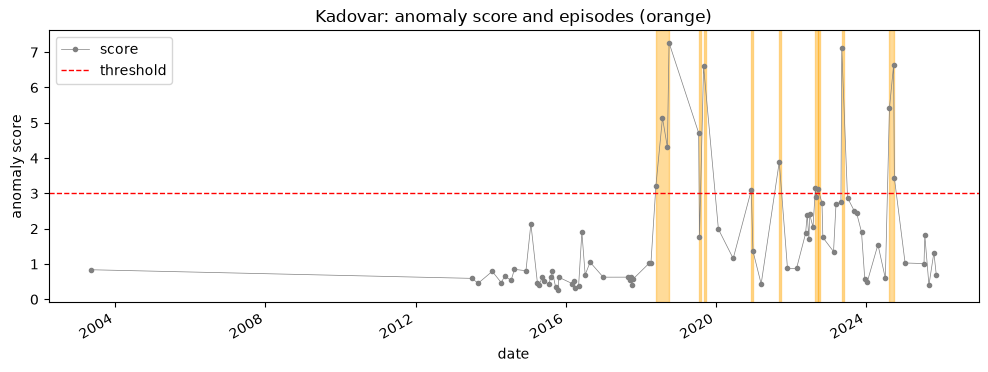

In [4]:
fig, ax = plt.subplots(figsize=(12, 4))
score.plot(ax=ax, marker=".", lw=0.5, c="gray")
ax.axhline(3, c="red", ls="--", lw=1, label="threshold")
for _, episode in episodes.iterrows():
    # single-scene episodes get a little width so they show up
    end = max(episode["end"], episode["start"] + np.timedelta64(20, "D"))
    ax.axvspan(episode["start"], end, color="orange", alpha=0.4)
ax.set_ylabel("anomaly score")
ax.set_title("Kadovar: anomaly score and episodes (orange)")
ax.legend()

Kadovar's first known historical eruption began in early 2018, and it stands out as the first multi-scene episode, from 2018-05-27 to 2018-10-02. Another multi-scene episode follows in 2024.

Note the dates: the corrupted rays that [rays.ipynb](rays.ipynb) flags on Kadovar fall *inside* these episodes. The episodes don't come from the corruption (those rays were masked, and the score uses the median of the 8 directions); rather, the corruption seems to show up when the scene is unusually hot, which hints at a processing problem with very hot pixels:

In [5]:
raw = volcanicus.datasets.load("kadovar")
flags = raw.flag_rays()
flagged_dates = flags[flags].index.unique("date")


def in_episode(date):
    inside = (episodes["start"] <= date) & (date <= episodes["end"])
    return inside.any()


pd.DataFrame(
    {
        "score": score.reindex(flagged_dates).round(1),
        "in_episode": [in_episode(d) for d in flagged_dates],
    },
    index=flagged_dates,
)

,score,in_episode
date,,
2015-06-04,0.5,False
2015-07-22,0.4,False
2015-08-23,0.8,False
2015-09-24,0.4,False
2017-08-28,0.6,False
2018-05-27,3.2,True
2018-07-30,5.1,True
2024-08-15,5.4,True
2024-09-24,6.6,True


## ⚠️ Single-scene episodes are mostly noise

With a threshold of 3, a few percent of perfectly ordinary scenes cross it by chance. Each of those becomes a one-scene episode. Across every dataset (this takes a while):

In [6]:
all_episodes, crossing = [], []
for name in volcanicus.datasets.available():
    v = volcanicus.datasets.load(name).mask_rays()
    s = v.scenes_anomaly_score().dropna()
    crossing.append((s > 3).mean())
    e = v.episodes()
    e["volcano"] = name
    if len(e):
        all_episodes.append(e)
all_episodes = pd.concat(all_episodes, ignore_index=True)

single = (all_episodes["n_scenes"] == 1).sum()
print(f"episodes: {len(all_episodes)}, single-scene: {single}")
print(f"median share of scenes above 3: {pd.Series(crossing).median():.1%}")

episodes: 655, single-scene: 546
median share of scenes above 3: 3.9%


Most episodes are a single scene, roughly what chance crossings alone would produce. Two or more consecutive anomalous scenes are much harder to get by chance, so `n_scenes >= 2` is a sensible filter. The longest multi-scene episodes across the bundled data:

In [7]:
multi = all_episodes[all_episodes["n_scenes"] >= 2]
print(multi["volcano"].nunique(), "volcanoes with multi-scene episodes")
multi.sort_values("n_scenes", ascending=False).head(10)[
    ["volcano", "start", "end", "n_scenes", "peak_score"]
].round(1)

57 volcanoes with multi-scene episodes


,volcano,start,end,n_scenes,peak_score
311,lewotolok,2023-06-13,2023-10-19,8,8.5
606,taal,2021-07-20,2022-03-17,7,8.6
570,sinabung,2016-03-11,2016-09-03,7,15.3
272,klyuchevskoy,2016-06-21,2016-09-02,6,11.4
78,bogoslof,2017-04-09,2017-09-16,6,8.0
313,lewotolok,2025-06-26,2025-09-30,6,11.9
277,krakatau,2018-07-29,2018-12-20,6,7.9
518,sangeang_api,2018-06-12,2018-12-21,6,7.8
440,papandayan,2002-05-24,2002-10-15,6,6.3
515,sangeang_api,2015-06-28,2015-10-26,5,8.2


Several of these line up with documented eruptions, e.g. Anak Krakatau in the second half of 2018 (the episode ends days before its December flank collapse) or Bogoslof in 2017. That's a plausibility check, not a validation: matching episodes against an eruption catalog (e.g. the Global Volcanism Program) would be the next step.

## `how="max"`: catching one-sided heat

Reducing directions with the maximum instead of the median makes a single hot direction enough. It finds more and longer episodes (the anomalous stretches merge), and part of that is chance: the maximum of 8 noisy values is easily large:

In [8]:
pd.DataFrame(
    {
        how: volcano.episodes(how=how)["n_scenes"].value_counts()
        for how in ["median", "max"]
    }
).fillna(0).astype(int).rename_axis("n_scenes")

,median,max
n_scenes,,
1,7,8
2,0,7
3,1,3
4,1,0
6,0,1
10,0,2


## ⚠️ Other caveats

- **Episodes are relative to the volcano's usual state** (see [anomalies.ipynb](anomalies.ipynb)). A volcano active in most of its scenes rarely shows episodes, because active *is* its normal.
- **Start, end and duration are bounds.** They're the first and last *observed* anomalous scenes; with a satellite pass every 16 days at best (and clouds), the real event started earlier and ended later.
- **Saturation hides intensity.** Saturated cells have no anomaly, so on lava-dominated volcanoes the score comes from the unsaturated cells around them.
- **`threshold` and `max_gap` are judgement calls**, hence parameters: raise `threshold` for fewer, stronger episodes; raise `max_gap` to bridge longer observation gaps.

## Next steps

- [anomalies.ipynb](anomalies.ipynb) for the baseline and anomalies the score is built on.
- [rays.ipynb](rays.ipynb) for `mask_rays()`.